In [1]:
import os
from pathlib import Path
print(f'Changing to {Path().resolve().parent}')
os.chdir(Path().resolve().parent)

Changing to /home/thijs/Documents/Code/HALCYON/HALCYON


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import networkx as nx
import numpy as np
from scipy.integrate import solve_ivp
from sympy import symbols, sympify
import torch
import re
import sys

# from halcyon.Models.MechanisticModel import ComplexODEModel, SBMLImportClassDummy
# from halcyon.RegulatoryNetwork import RegulatoryNetwork
import libsbml
# from sympy.parsing.sympy_parser import parse_expr

In [3]:
print(sys.version)
folder_path = "tests/6_gene_testv2/"
# folder_path = "tests/genenetweaver_outputs/"
sbml_path = folder_path + "test_scalefree.xml"
# sbml_path = "tests/models/pokhilko2012.xml"

3.12.3 | packaged by conda-forge | (main, Apr 15 2024, 18:38:13) [GCC 12.3.0]


In [4]:
# def test_import_from_sbml():
#     # sbml_path = "tests/genenetweaver_outputs/test_scalefree.xml"
#     # sbml_path = "tests/models/pokhilko2012.xml"
#     my_importclass_test = SBMLImportClassDummy.from_sbml(sbml_path)
#     return my_importclass_test

In [5]:
# imported = test_import_from_sbml()
# print(imported)

In [6]:
reader = libsbml.SBMLReader()
document = reader.readSBML(sbml_path)  # type: ignore
model = document.getModel()
print(model.getNumReactions())
parameter_list = model.getListOfParameters()
# To get the parameters of the model, you can use getListOfParameters()
parameters = model.getListOfParameters()
print(f"Number of parameters in the model: {parameters.size()}")
for i in range(parameters.size()):
    param = parameters.get(i)
    print(f"Parameter id: {param.getId()}, value: {param.getValue()}")

12
Number of parameters in the model: 0


In [7]:
#install tellurium: https://tellurium.readthedocs.io/en/latest/installation.html
import tellurium as te

print(te.getVersionInfo())

# Load the SBML model from a file
# sbml_file = sys.argv[1]
model = te.loadSBMLModel(sbml_path)

# model.selections = ['cCOP1c', 'cCOP1d', 'cCOP1n', 'cE3', 'cE3_m', 'cE3n', 'cE4', 'cE4_m', 'cEC', 'cEG', 'cG', 'cG_m', 'cL', 'cLUX', 'cLUX_m', 'cL_m', 'cLm', 'cNI', 'cNI_m', 'cP', 'cP7', 'cP7_m', 'cP9', 'cP9_m', 'cT', 'cT_m', 'cZG', 'cZTL']
# model.selections = ['cP', 'cP7', 'cP7_m', 's1', 's15', 's37']

# Reset model to its initial state (species initialized as per model)
# model.reset()

# Print initial concentrations of all species
species = model.getFloatingSpeciesIds()
for s in species:
    print(f"{s} initial value: {model[s]}")
# print(species)

# Load initial values from TSV file
init_df = pd.read_csv(folder_path + "test_scalefree_nonoise_wildtype.tsv", sep="\t")
# Assume columns are node_names and values are in the first row
y0 = init_df.loc[0, species].values.astype(float)

for i, sp in enumerate(species):
    model[sp] = y0[i]
    
# Print initial concentrations of all species
species = model.getFloatingSpeciesIds()
for s in species:
    print(f"{s} initial value: {model[s]}")
print(species)


[('tellurium', '2.2.11.1'), ('roadrunner', '2.8.0'), ('antimony', '3.0.0'), ('libsbml', '5.20.2'), ('libsedml', '2.0.33'), ('phrasedml', '1.3.0')]
Node_0 initial value: 0.0
Node_1 initial value: 0.0
Node_2 initial value: 0.0
Node_3 initial value: 0.0
Node_4 initial value: 0.0
Node_5 initial value: 0.0
Node_0 initial value: 0.1780818
Node_1 initial value: 0.9222381
Node_2 initial value: 0.1129278
Node_3 initial value: 1.0
Node_4 initial value: 0.1310036
Node_5 initial value: 0.8210416
['Node_0', 'Node_1', 'Node_2', 'Node_3', 'Node_4', 'Node_5']


In [8]:
display(te.getODEsFromSBMLFile(sbml_path))

'\nvNode_0_synthesis = cell*max*(a_0*(1-pow(Node_1/k_1,n_1)/(1+pow(Node_1/k_1,n_1)))*(1-pow(Node_2/k_2,n_2)/(1+pow(Node_2/k_2,n_2)))+a_1*(pow(Node_1/k_1,n_1)/(1+pow(Node_1/k_1,n_1)))*(1-pow(Node_2/k_2,n_2)/(1+pow(Node_2/k_2,n_2)))+a_2*(1-pow(Node_1/k_1,n_1)/(1+pow(Node_1/k_1,n_1)))*(pow(Node_2/k_2,n_2)/(1+pow(Node_2/k_2,n_2)))+a_3*(pow(Node_1/k_1,n_1)/(1+pow(Node_1/k_1,n_1)))*(pow(Node_2/k_2,n_2)/(1+pow(Node_2/k_2,n_2))))\nvNode_0_degradation = cell*delta*Node_0\nvNode_1_synthesis = cell*max*(a_0*(1-pow(Node_2/k_1,n_1)*pow(Node_0/k_2,n_2)*pow(Node_3/k_3,n_3)/(1+pow(Node_2/k_1,n_1))*(1+pow(Node_0/k_2,n_2))*(1+pow(Node_3/k_3,n_3)))+a_1*(pow(Node_2/k_1,n_1)*pow(Node_0/k_2,n_2)*pow(Node_3/k_3,n_3)/(1+pow(Node_2/k_1,n_1))*(1+pow(Node_0/k_2,n_2))*(1+pow(Node_3/k_3,n_3))))\nvNode_1_degradation = cell*delta*Node_1\nvNode_2_synthesis = cell*max*(a_0*(1-pow(Node_1/k_1,n_1)/(1+pow(Node_1/k_1,n_1)))+a_1*(pow(Node_1/k_1,n_1)/(1+pow(Node_1/k_1,n_1))))\nvNode_2_degradation = cell*delta*Node_2\nvNode_

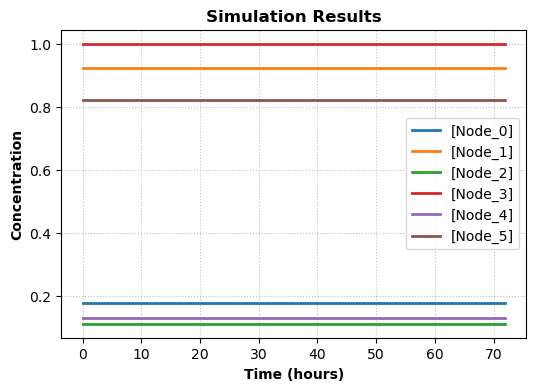

In [9]:
#This script will import an SBML model (eg from GeneNetWeaver) and simulate it.




# Simulate the model
result = model.simulate(0, 72, 1000)  # Simulate from time 0 to 96 with 1000 points

# Plot the results

# Plot with axis labels
model.plot(result, xlabel='Time (hours)', ylabel='Concentration', title='Simulation Results', grid=True)